In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
train = pd.read_csv("food_delivery_train.csv")

test = pd.read_csv('food_delivery_test.csv')

print("Dataset loaded successfully")

Dataset loaded successfully


In [13]:
print("Training Dataset shape:", train.shape)

print("Testing Dataset shape:", test.shape)

Training Dataset shape: (1000, 13)
Testing Dataset shape: (250, 13)


In [14]:
train.head()

,order_id,delivery_person_age,delivery_person_rating,distance_km,restaurant_preparation_time_min,traffic_level,weather,vehicle_type,order_hour,is_weekend,is_festival,multiple_deliveries,delivery_time_min
0,1,43,4.6,14.04,27,High,Cloudy,Motorcycle,15,Yes,No,No,77
1,2,40,3.6,8.18,6,Medium,Clear,Scooter,14,No,No,No,33
2,3,48,4.9,15.53,15,Medium,Rainy,Scooter,9,No,No,No,69
3,4,49,4.1,12.70,16,High,Clear,Motorcycle,9,Yes,No,No,61
4,5,41,2.8,2.15,25,Low,Cloudy,Motorcycle,16,Yes,No,No,38


In [15]:
train.tail()

,order_id,delivery_person_age,delivery_person_rating,distance_km,restaurant_preparation_time_min,traffic_level,weather,vehicle_type,order_hour,is_weekend,is_festival,multiple_deliveries,delivery_time_min
995,996,29,3.7,8.16,21,Low,Clear,Motorcycle,15,Yes,No,No,46
996,997,18,4.1,11.68,12,Low,Clear,Scooter,10,No,No,No,45
997,998,45,3.0,0.54,14,Medium,Clear,Scooter,13,No,No,No,23
998,999,42,4.9,17.88,16,Medium,Clear,Scooter,11,No,No,Yes,67
999,1000,35,2.7,5.42,22,Low,Cloudy,Scooter,16,No,No,No,39


In [16]:
train.sample(5)

,order_id,delivery_person_age,delivery_person_rating,distance_km,restaurant_preparation_time_min,traffic_level,weather,vehicle_type,order_hour,is_weekend,is_festival,multiple_deliveries,delivery_time_min
824,825,37,5.0,15.13,21,High,Clear,Motorcycle,15,Yes,No,No,66
968,969,37,3.9,10.20,23,Medium,Clear,Scooter,8,Yes,No,No,66
924,925,39,2.6,3.39,15,Low,Clear,Motorcycle,12,Yes,No,No,27
543,544,43,3.1,17.83,14,Medium,Cloudy,Scooter,11,No,No,No,64
453,454,29,4.5,3.53,17,Low,Cloudy,Motorcycle,15,No,No,Yes,31


In [17]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   order_id                         1000 non-null   int64  
 1   delivery_person_age              1000 non-null   int64  
 2   delivery_person_rating           1000 non-null   float64
 3   distance_km                      1000 non-null   float64
 4   restaurant_preparation_time_min  1000 non-null   int64  
 5   traffic_level                    1000 non-null   str    
 6   weather                          1000 non-null   str    
 7   vehicle_type                     1000 non-null   str    
 8   order_hour                       1000 non-null   int64  
 9   is_weekend                       1000 non-null   str    
 10  is_festival                      1000 non-null   str    
 11  multiple_deliveries              1000 non-null   str    
 12  delivery_time_min               

In [18]:
train.describe()

,order_id,delivery_person_age,delivery_person_rating,distance_km,restaurant_preparation_time_min,order_hour,delivery_time_min
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,34.043000,3.731500,9.200610,17.599000,14.777000,54.652000
std,288.819436,9.437172,0.724764,5.102705,7.510033,4.344208,16.413723
min,1.000000,18.000000,2.500000,0.520000,5.000000,8.000000,11.000000
25%,250.750000,25.000000,3.100000,4.700000,11.000000,11.000000,43.000000
50%,500.500000,34.000000,3.700000,9.160000,17.000000,15.000000,54.000000
75%,750.250000,42.000000,4.400000,13.777500,24.000000,19.000000,66.000000
max,1000.000000,50.000000,5.000000,17.980000,30.000000,22.000000,106.000000


In [19]:
print(train.isnull().sum())

order_id                           0
delivery_person_age                0
delivery_person_rating             0
distance_km                        0
restaurant_preparation_time_min    0
traffic_level                      0
weather                            0
vehicle_type                       0
order_hour                         0
is_weekend                         0
is_festival                        0
multiple_deliveries                0
delivery_time_min                  0
dtype: int64


In [20]:
print("Duplicate rows:", train.duplicated().sum())

Duplicate rows: 0


In [21]:
target = "delivery_time_min"

print("target variable:", target)

target variable: delivery_time_min


In [22]:
x = train.drop(
    columns = ['delivery_time_min','order_id']
)

y = train['delivery_time_min']

print("Features Shape:", x.shape)

print("Target shape:", y.shape)

Features Shape: (1000, 11)
Target shape: (1000,)


In [23]:
print("Age below 18 or above 60:")
print(train[
    (train["delivery_person_age"]<18)|
    (train["delivery_person_age"]>60)
])

print("Invalid ratings:")
print(train[
    (train["delivery_person_rating"] < 1) |
    (train["delivery_person_rating"] > 5)
])

print("Invalid distances:")
print(train[train["distance_km"] <= 0])

print("Invalid preparation times:")
print(train[
    train["restaurant_preparation_time_min"] <= 0
])

print("Invalid delivery times:")
print(train[train["delivery_time_min"] <= 0])


Age below 18 or above 60:
Empty DataFrame
Columns: [order_id, delivery_person_age, delivery_person_rating, distance_km, restaurant_preparation_time_min, traffic_level, weather, vehicle_type, order_hour, is_weekend, is_festival, multiple_deliveries, delivery_time_min]
Index: []
Invalid ratings:
Empty DataFrame
Columns: [order_id, delivery_person_age, delivery_person_rating, distance_km, restaurant_preparation_time_min, traffic_level, weather, vehicle_type, order_hour, is_weekend, is_festival, multiple_deliveries, delivery_time_min]
Index: []
Invalid distances:
Empty DataFrame
Columns: [order_id, delivery_person_age, delivery_person_rating, distance_km, restaurant_preparation_time_min, traffic_level, weather, vehicle_type, order_hour, is_weekend, is_festival, multiple_deliveries, delivery_time_min]
Index: []
Invalid preparation times:
Empty DataFrame
Columns: [order_id, delivery_person_age, delivery_person_rating, distance_km, restaurant_preparation_time_min, traffic_level, weather, vehi

In [24]:
categorical_columns = [
    "traffic_level",
    "weather",
    "vehicle_type",
    "is_weekend",
    "is_festival",
    "multiple_deliveries"
]

for col in categorical_columns:

    print("\nColumn:", col)

    print(train[col].unique())


Column: traffic_level
<StringArray>
['High', 'Medium', 'Low', 'Jam']
Length: 4, dtype: str

Column: weather
<StringArray>
['Cloudy', 'Clear', 'Rainy', 'Foggy']
Length: 4, dtype: str

Column: vehicle_type
<StringArray>
['Motorcycle', 'Scooter', 'Bicycle']
Length: 3, dtype: str

Column: is_weekend
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Column: is_festival
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Column: multiple_deliveries
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [25]:
# Select numerical columns
numerical_columns = [
    "delivery_person_age",
    "delivery_person_rating",
    "distance_km",
    "restaurant_preparation_time_min",
    "order_hour",
    "delivery_time_min"
]

for col in numerical_columns:

    Q1 = train[col].quantile(0.25)

    Q3 = train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR

    upper_limit = Q3 + 1.5 * IQR

    outliers = train[
        (train[col] < lower_limit) |
        (train[col] > upper_limit)
    ]

    print("\nColumn:", col)

    print("Outliers:", len(outliers))

    print("Lower limit:", lower_limit)

    print("Upper limit:", upper_limit)


Column: delivery_person_age
Outliers: 0
Lower limit: -0.5
Upper limit: 67.5

Column: delivery_person_rating
Outliers: 0
Lower limit: 1.1499999999999997
Upper limit: 6.3500000000000005

Column: distance_km
Outliers: 0
Lower limit: -8.916250000000002
Upper limit: 27.39375

Column: restaurant_preparation_time_min
Outliers: 0
Lower limit: -8.5
Upper limit: 43.5

Column: order_hour
Outliers: 0
Lower limit: -1.0
Upper limit: 31.0

Column: delivery_time_min
Outliers: 1
Lower limit: 8.5
Upper limit: 100.5


In [26]:
print("Train Columns:")
print(train.columns.tolist())

print("\nTest Columns:")
print(test.columns.tolist())

Train Columns:
['order_id', 'delivery_person_age', 'delivery_person_rating', 'distance_km', 'restaurant_preparation_time_min', 'traffic_level', 'weather', 'vehicle_type', 'order_hour', 'is_weekend', 'is_festival', 'multiple_deliveries', 'delivery_time_min']

Test Columns:
['order_id', 'delivery_person_age', 'delivery_person_rating', 'distance_km', 'restaurant_preparation_time_min', 'traffic_level', 'weather', 'vehicle_type', 'order_hour', 'is_weekend', 'is_festival', 'multiple_deliveries', 'delivery_time_min']


In [27]:
print(
    "Same Columns:",
    set(train.columns) == set(test.columns)
)

Same Columns: True


In [28]:
target = "delivery_time_min"

X_train = train.drop(
    columns=["delivery_time_min", "order_id"]
)

y_train = train[target]

X_test = test.drop(
    columns=["delivery_time_min", "order_id"]
)

y_test = test[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1000, 11)
y_train: (1000,)
X_test: (250, 11)
y_test: (250,)


In [29]:
train.to_csv(
    "food_delivery_train_clean.csv",
    index=False
)

test.to_csv(
    "food_delivery_test_clean.csv",
    index=False
)

print("Clean datasets saved successfully!")

Clean datasets saved successfully!


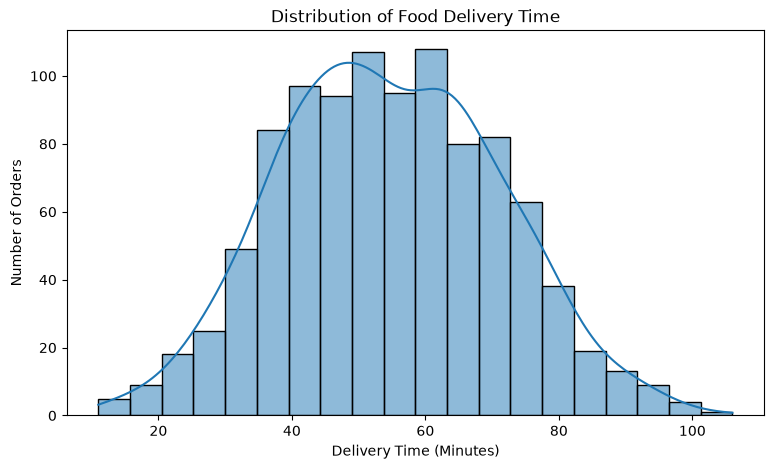

In [30]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=train,
    x="delivery_time_min",
    bins=20,
    kde=True
)

plt.title("Distribution of Food Delivery Time")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Orders")

plt.show()

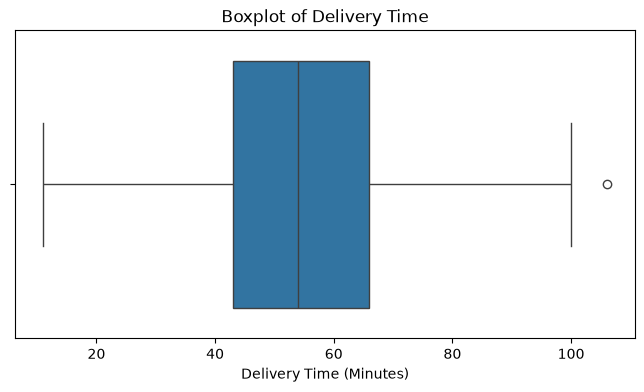

In [31]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=train,
    x="delivery_time_min"
)

plt.title("Boxplot of Delivery Time")
plt.xlabel("Delivery Time (Minutes)")

plt.show()

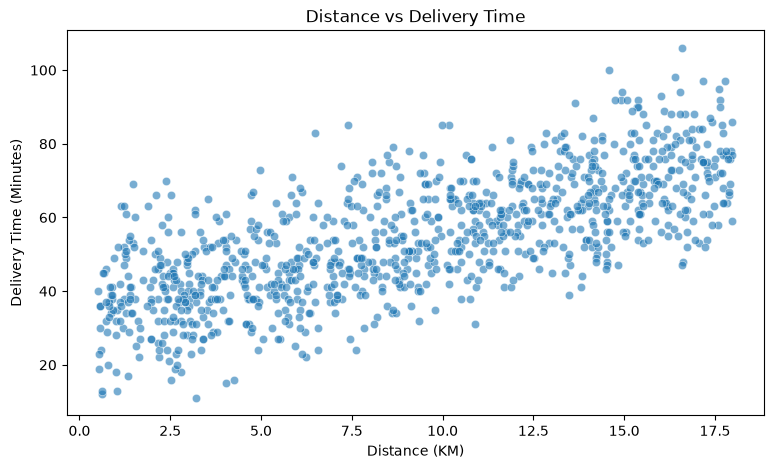

In [32]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=train,
    x="distance_km",
    y="delivery_time_min",
    alpha=0.6
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (KM)")
plt.ylabel("Delivery Time (Minutes)")

plt.show()

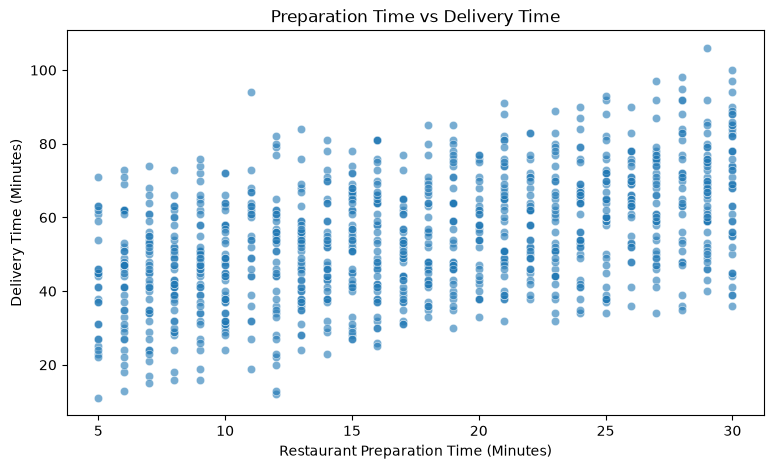

In [33]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=train,
    x="restaurant_preparation_time_min",
    y="delivery_time_min",
    alpha=0.6
)

plt.title("Preparation Time vs Delivery Time")
plt.xlabel("Restaurant Preparation Time (Minutes)")
plt.ylabel("Delivery Time (Minutes)")

plt.show()

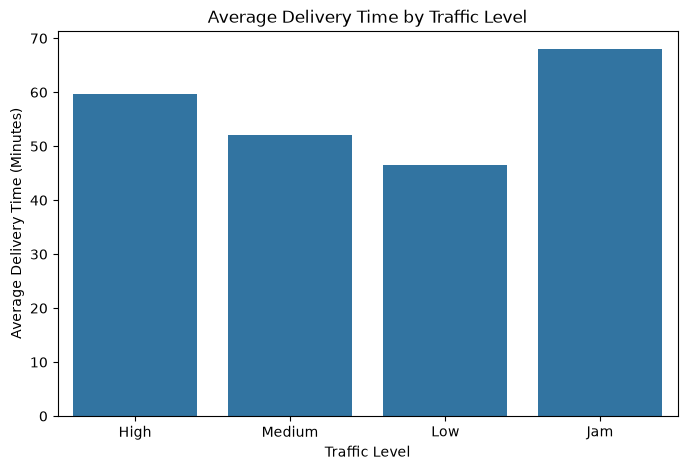

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x="traffic_level",
    y="delivery_time_min",
    errorbar=None
)

plt.title("Average Delivery Time by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Average Delivery Time (Minutes)")

plt.show()

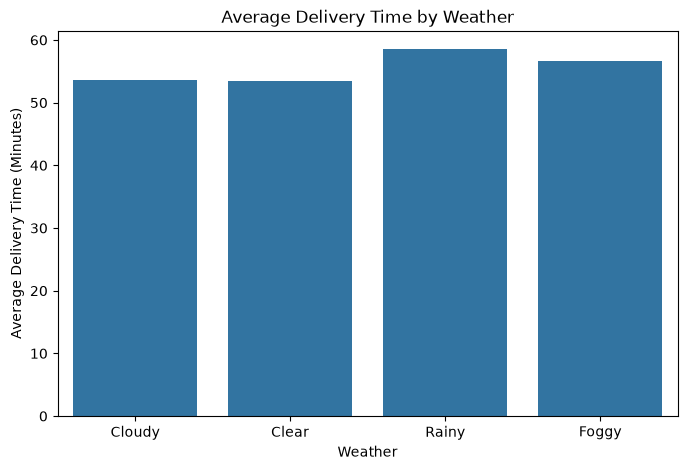

In [35]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x="weather",
    y="delivery_time_min",
    errorbar=None
)

plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather")
plt.ylabel("Average Delivery Time (Minutes)")

plt.show()

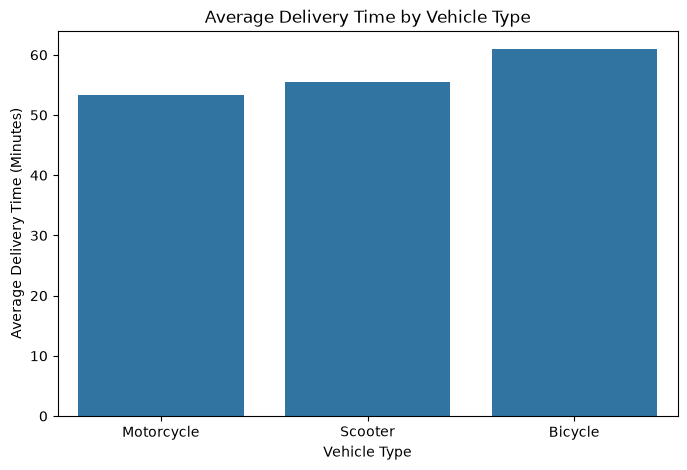

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x="vehicle_type",
    y="delivery_time_min",
    errorbar=None
)

plt.title("Average Delivery Time by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Delivery Time (Minutes)")

plt.show()

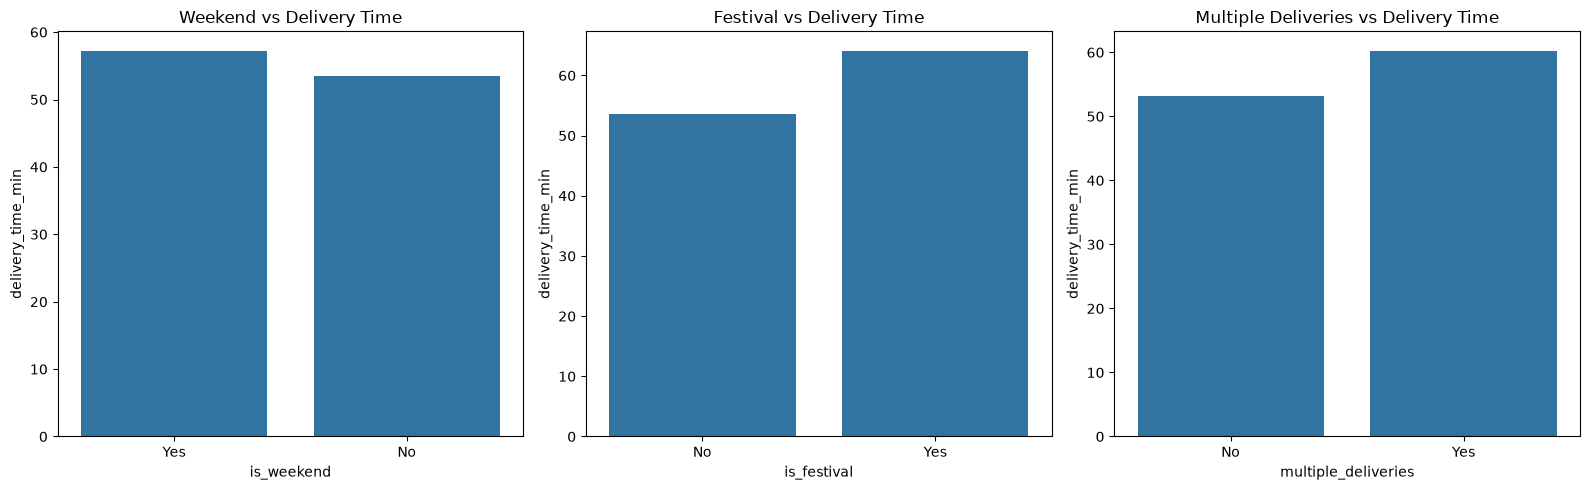

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(data=train, x="is_weekend",
            y="delivery_time_min", errorbar=None, ax=axes[0])
axes[0].set_title("Weekend vs Delivery Time")

sns.barplot(data=train, x="is_festival",
            y="delivery_time_min", errorbar=None, ax=axes[1])
axes[1].set_title("Festival vs Delivery Time")

sns.barplot(data=train, x="multiple_deliveries",
            y="delivery_time_min", errorbar=None, ax=axes[2])
axes[2].set_title("Multiple Deliveries vs Delivery Time")

plt.tight_layout()
plt.show()

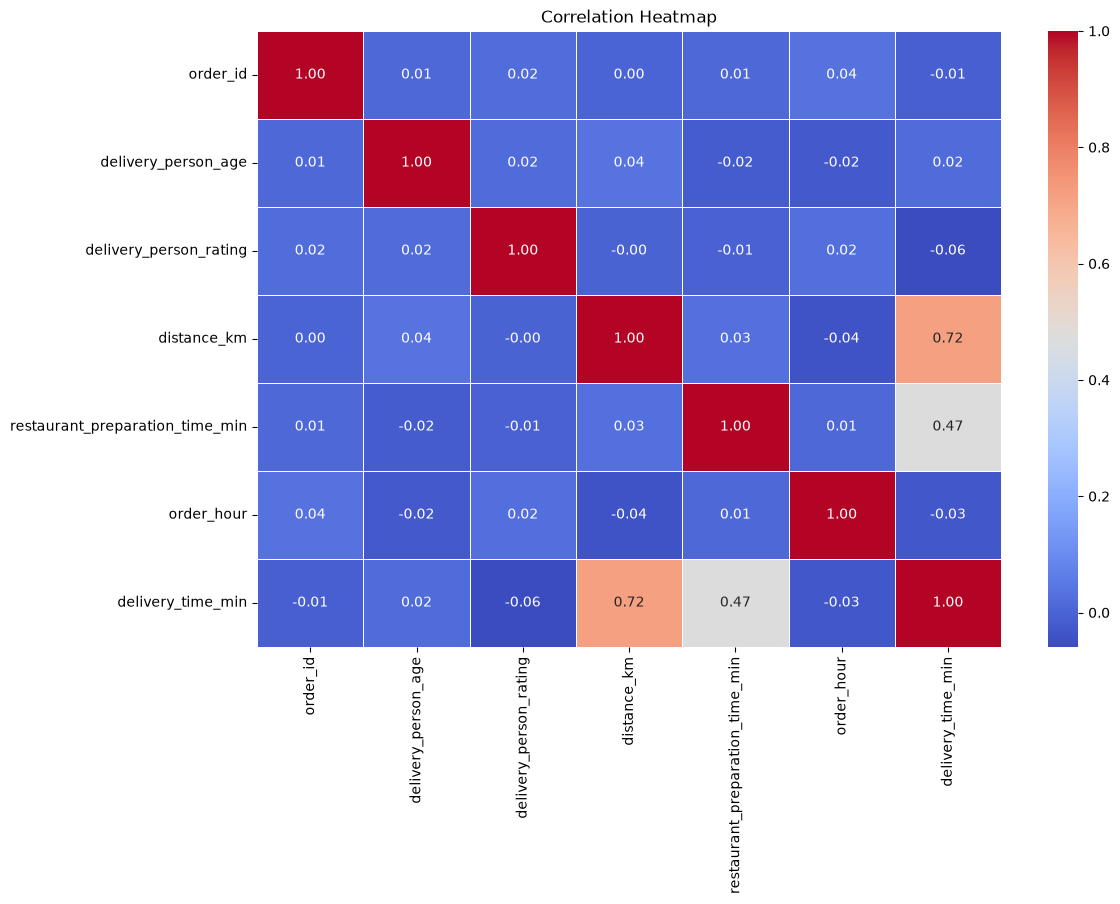

In [38]:
# Select numerical columns
numeric_data = train.select_dtypes(include="number")

# Calculate correlation
correlation = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

In [39]:
categorical_columns = [
    "traffic_level",
    "weather",
    "vehicle_type",
    "is_weekend",
    "is_festival",
    "multiple_deliveries"
]

for column in categorical_columns:
    print(f"\n{column.upper()}")
    print(train[column].value_counts())


TRAFFIC_LEVEL
traffic_level
Medium    378
High      292
Low       227
Jam       103
Name: count, dtype: int64

WEATHER
weather
Clear     502
Cloudy    254
Rainy     194
Foggy      50
Name: count, dtype: int64

VEHICLE_TYPE
vehicle_type
Motorcycle    582
Scooter       332
Bicycle        86
Name: count, dtype: int64

IS_WEEKEND
is_weekend
No     704
Yes    296
Name: count, dtype: int64

IS_FESTIVAL
is_festival
No     902
Yes     98
Name: count, dtype: int64

MULTIPLE_DELIVERIES
multiple_deliveries
No     792
Yes    208
Name: count, dtype: int64


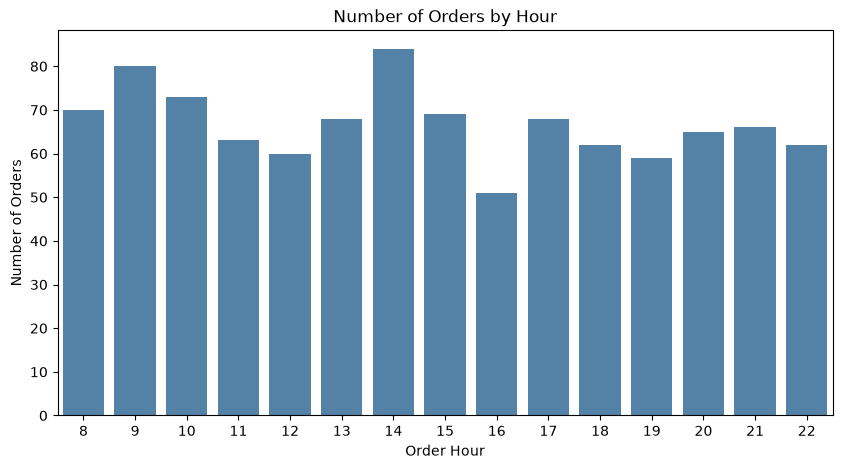

In [40]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=train,
    x="order_hour",
    color="steelblue"
)

plt.title("Number of Orders by Hour")
plt.xlabel("Order Hour")
plt.ylabel("Number of Orders")

plt.show()

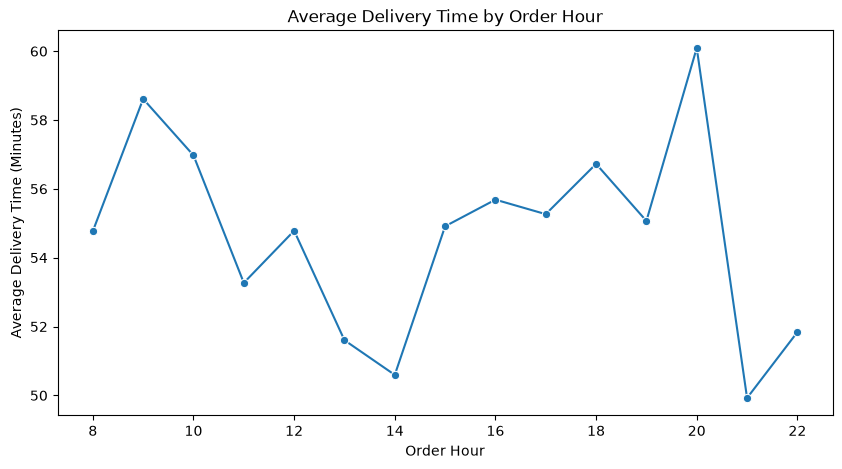

In [41]:
hourly_delivery = (
    train.groupby("order_hour")["delivery_time_min"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=hourly_delivery,
    x="order_hour",
    y="delivery_time_min",
    marker="o"
)

plt.title("Average Delivery Time by Order Hour")
plt.xlabel("Order Hour")
plt.ylabel("Average Delivery Time (Minutes)")

plt.show()

In [42]:
plt.savefig("../delivery_time_distribution.png",
            dpi=300,
            bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [43]:
import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

import joblib

In [44]:
# Input features
X_train = train.drop(
    columns=["delivery_time_min", "order_id"]
)

# Target variable
y_train = train["delivery_time_min"]

# Test input features
X_test = test.drop(
    columns=["delivery_time_min", "order_id"]
)

# Test target
y_test = test["delivery_time_min"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1000, 11)
y_train: (1000,)
X_test: (250, 11)
y_test: (250,)


In [45]:
# Numerical columns
numerical_columns = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Categorical columns
categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['delivery_person_age', 'delivery_person_rating', 'distance_km', 'restaurant_preparation_time_min', 'order_hour']

Categorical Columns:
['traffic_level', 'weather', 'vehicle_type', 'is_weekend', 'is_festival', 'multiple_deliveries']


C:\Users\LALIT\AppData\Local\Temp\ipykernel_19956\2933211928.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


In [46]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [47]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [48]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numeric_pipeline, numerical_columns),
        ("categorical", categorical_pipeline, categorical_columns)
    ]
)

In [49]:
# Learn preprocessing rules from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same rules to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (1000, 22)
Processed testing shape: (250, 22)


In [50]:
# Correct
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Incorrect for this workflow
# X_test_processed = preprocessor.fit_transform(X_test)

In [51]:
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nTraining data type:")
print(type(X_train_processed))

print("\nFirst 5 transformed rows:")
print(X_train_processed[:5])

Training data shape: (1000, 22)
Testing data shape: (250, 22)

Training data type:
<class 'numpy.ndarray'>

First 5 transformed rows:
[[ 0.94959402  1.19892052  0.94887159  1.25241842  0.0513584   1.
   0.          0.          0.          0.          1.          0.
   0.          0.          1.          0.          0.          1.
   1.          0.          1.          0.        ]
 [ 0.6315431  -0.18152913 -0.20011362 -1.54524001 -0.17894834  0.
   0.          0.          1.          1.          0.          0.
   0.          0.          0.          1.          1.          0.
   1.          0.          1.          0.        ]
 [ 1.47967888  1.61305541  1.24101971 -0.34624354 -1.33048203  0.
   0.          0.          1.          0.          0.          0.
   1.          0.          0.          1.          1.          0.
   1.          0.          1.          0.        ]
 [ 1.58569585  0.50869569  0.68613436 -0.21302171 -1.33048203  1.
   0.          0.          0.          1.          0.

In [52]:
feature_names = preprocessor.get_feature_names_out()

print("Total features:", len(feature_names))

for name in feature_names:
    print(name)

Total features: 22
numerical__delivery_person_age
numerical__delivery_person_rating
numerical__distance_km
numerical__restaurant_preparation_time_min
numerical__order_hour
categorical__traffic_level_High
categorical__traffic_level_Jam
categorical__traffic_level_Low
categorical__traffic_level_Medium
categorical__weather_Clear
categorical__weather_Cloudy
categorical__weather_Foggy
categorical__weather_Rainy
categorical__vehicle_type_Bicycle
categorical__vehicle_type_Motorcycle
categorical__vehicle_type_Scooter
categorical__is_weekend_No
categorical__is_weekend_Yes
categorical__is_festival_No
categorical__is_festival_Yes
categorical__multiple_deliveries_No
categorical__multiple_deliveries_Yes


In [53]:
joblib.dump(
    preprocessor,
    "food_delivery_preprocessor.pkl"
)

['food_delivery_preprocessor.pkl']

In [54]:
# Check dimensions
assert X_train_processed.shape[0] == len(y_train)
assert X_test_processed.shape[0] == len(y_test)

# Check feature count consistency
assert X_train_processed.shape[1] == X_test_processed.shape[1]

# Check missing values in transformed data
print("Train contains NaN:", np.isnan(X_train_processed).any())
print("Test contains NaN:", np.isnan(X_test_processed).any())

print("\nPreprocessing completed successfully!")

Train contains NaN: False
Test contains NaN: False

Preprocessing completed successfully!


In [55]:

from sklearn.model_selection import train_test_split

# Original training features and target
X = X_train.copy()
y = y_train.copy()

# Split training data into training and validation
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", X_train_part.shape[0])
print("Validation rows:", X_val.shape[0])


Training rows: 800
Validation rows: 200


In [56]:

import pandas as pd
import numpy as np

from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [57]:

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}


In [58]:

results = []
trained_models = {}

for name, estimator in models.items():

    # Create a fresh preprocessing + model pipeline
    model_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("regressor", estimator)
    ])

    # Train model using training portion only
    model_pipeline.fit(X_train_part, y_train_part)

    # Predict delivery time on validation data
    predictions = model_pipeline.predict(X_val)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_val, predictions)
    mse = mean_squared_error(y_val, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_val, predictions)

    # Store results
    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    # Save trained model in dictionary
    trained_models[name] = model_pipeline

    print(name, "training completed")


Linear Regression training completed
Decision Tree training completed
Random Forest training completed
Gradient Boosting training completed


In [59]:

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

print(results_df.round(3))


               Model    MAE     MSE   RMSE  R2 Score
0  Linear Regression  3.041  13.902  3.729     0.948
3  Gradient Boosting  3.365  16.768  4.095     0.937
2      Random Forest  4.639  32.638  5.713     0.877
1      Decision Tree  7.518  85.538  9.249     0.677


In [60]:

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best model:", best_model_name)
print("Best validation RMSE:",
      results_df.iloc[0]["RMSE"])


Best model: Linear Regression
Best validation RMSE: 3.72859050027344


In [61]:

# Create a fresh pipeline for final training
final_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", clone(models[best_model_name]))
])

# Train using all training data
final_model.fit(X_train, y_train)

print("Final model training completed!")


Final model training completed!


In [62]:

# Predict on untouched test data
test_predictions = final_model.predict(X_test)

# Calculate final metrics
test_mae = mean_absolute_error(y_test, test_predictions)
test_mse = mean_squared_error(y_test, test_predictions)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, test_predictions)

print("Final Test Results")
print("------------------")
print("MAE:", round(test_mae, 3))
print("MSE:", round(test_mse, 3))
print("RMSE:", round(test_rmse, 3))
print("R2 Score:", round(test_r2, 3))


Final Test Results
------------------
MAE: 3.013
MSE: 14.139
RMSE: 3.76
R2 Score: 0.933


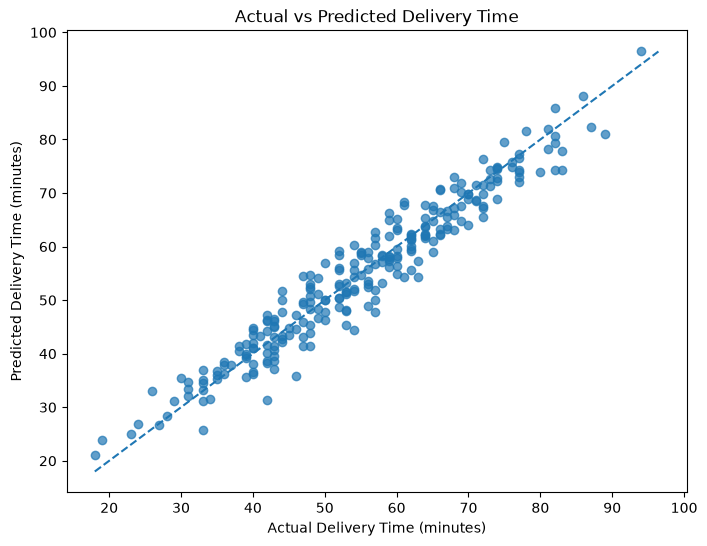

In [63]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.7
)

# Perfect prediction reference line
minimum = min(y_test.min(), test_predictions.min())
maximum = max(y_test.max(), test_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Time")

plt.show()


In [64]:

import joblib
import os

# Create models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Save final trained pipeline
joblib.dump(
    final_model,
    "../models/food_delivery_model.pkl"
)

print("Model saved successfully!")


Model saved successfully!


In [65]:
RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=2
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number

In [66]:

import pandas as pd
import numpy as np
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [67]:

base_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", RandomForestRegressor(random_state=42))
])


In [68]:

param_distributions = [

    # Decision Tree parameters
    {
        "regressor": [
            DecisionTreeRegressor(random_state=42)
        ],
        "regressor__max_depth": [3, 5, 8, None],
        "regressor__min_samples_split": [2, 5, 10],
        "regressor__min_samples_leaf": [1, 2, 4]
    },

    # Random Forest parameters
    {
        "regressor": [
            RandomForestRegressor(
                random_state=42,
                n_jobs=1
            )
        ],
        "regressor__n_estimators": [100, 200, 300],
        "regressor__max_depth": [None, 8, 12, 16],
        "regressor__min_samples_split": [2, 5, 10],
        "regressor__min_samples_leaf": [1, 2, 4],
        "regressor__max_features": [1.0, "sqrt"]
    },

    # Gradient Boosting parameters
    {
        "regressor": [
            GradientBoostingRegressor(random_state=42)
        ],
        "regressor__n_estimators": [100, 200, 300],
        "regressor__learning_rate": [0.03, 0.05, 0.1],
        "regressor__max_depth": [2, 3, 4],
        "regressor__subsample": [0.8, 1.0],
        "regressor__min_samples_leaf": [1, 2, 4]
    }
]


In [69]:

random_search = RandomizedSearchCV(
    estimator=base_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Fit using training data only
random_search.fit(X_train, y_train)

print("Tuning completed!")


Fitting 5 folds for each of 30 candidates, totalling 150 fits


Tuning completed!


In [70]:

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-random_search.best_score_)

best_tuned_model = random_search.best_estimator_

print("\nBest tuned model:")
print(best_tuned_model.named_steps["regressor"])


Best Parameters:
{'regressor__subsample': 0.8, 'regressor__n_estimators': 300, 'regressor__min_samples_leaf': 4, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.1, 'regressor': GradientBoostingRegressor(random_state=42)}

Best Cross-Validation RMSE:
3.6495327338089405

Best tuned model:
GradientBoostingRegressor(max_depth=2, min_samples_leaf=4, n_estimators=300,
                          random_state=42, subsample=0.8)


In [71]:

cv_results = pd.DataFrame(random_search.cv_results_)

comparison = cv_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "params"
    ]
].copy()

comparison["mean_RMSE"] = -comparison["mean_test_score"]

comparison = comparison.sort_values(
    by="rank_test_score"
)

print(comparison[
    ["rank_test_score", "mean_RMSE", "std_test_score", "params"]
].head(10).to_string(index=False))


 rank_test_score  mean_RMSE  std_test_score                                                                                                                                                                                                                params
               1   3.649533        0.058581  {'regressor__subsample': 0.8, 'regressor__n_estimators': 300, 'regressor__min_samples_leaf': 4, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.1, 'regressor': GradientBoostingRegressor(random_state=42)}
               2   3.677779        0.149651  {'regressor__subsample': 1.0, 'regressor__n_estimators': 300, 'regressor__min_samples_leaf': 1, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.1, 'regressor': GradientBoostingRegressor(random_state=42)}
               3   3.788641        0.071041  {'regressor__subsample': 0.8, 'regressor__n_estimators': 200, 'regressor__min_samples_leaf': 4, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.1, 'regressor': GradientBoos

In [72]:

# Predict on test data
tuned_predictions = best_tuned_model.predict(X_test)

# Calculate metrics
tuned_mae = mean_absolute_error(y_test, tuned_predictions)

tuned_mse = mean_squared_error(y_test, tuned_predictions)

tuned_rmse = np.sqrt(tuned_mse)

tuned_r2 = r2_score(y_test, tuned_predictions)

print("Tuned Model Test Results")
print("------------------------")
print("MAE:", round(tuned_mae, 3))
print("MSE:", round(tuned_mse, 3))
print("RMSE:", round(tuned_rmse, 3))
print("R2 Score:", round(tuned_r2, 3))


Tuned Model Test Results
------------------------
MAE: 2.625
MSE: 11.052
RMSE: 3.324
R2 Score: 0.948


In [73]:

comparison_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Step 5 Model": [
        test_mae,
        test_rmse,
        test_r2
    ],
    "Step 6 Tuned Model": [
        tuned_mae,
        tuned_rmse,
        tuned_r2
    ]
})

print(comparison_df.round(3))


     Metric  Step 5 Model  Step 6 Tuned Model
0       MAE         3.013               2.625
1      RMSE         3.760               3.324
2  R2 Score         0.933               0.948


In [74]:

import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_tuned_model,
    "../models/food_delivery_tuned_model.pkl"
)

print("Tuned model saved successfully!")


Tuned model saved successfully!


In [75]:

from sklearn.inspection import permutation_importance

sns.set_style("whitegrid")

In [76]:
import joblib

best_tuned_model = joblib.load(
    "../models/food_delivery_tuned_model.pkl"
)

test_predictions = best_tuned_model.predict(X_test)

In [77]:

# Calculate permutation importance on test data
importance_result = permutation_importance(
    best_tuned_model,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create importance table
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

# Sort from highest to lowest
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.round(4))


                            Feature  Importance     Std
2                       distance_km     12.1337  0.5435
3   restaurant_preparation_time_min      7.8593  0.3831
4                     traffic_level      4.5377  0.2538
5                           weather      1.6793  0.1594
6                      vehicle_type      1.5440  0.1427
10              multiple_deliveries      1.3552  0.1473
7                        order_hour      1.2069  0.0886
9                       is_festival      0.9586  0.1366
1            delivery_person_rating      0.3519  0.0520
8                        is_weekend      0.1511  0.0517
0               delivery_person_age      0.0560  0.0354


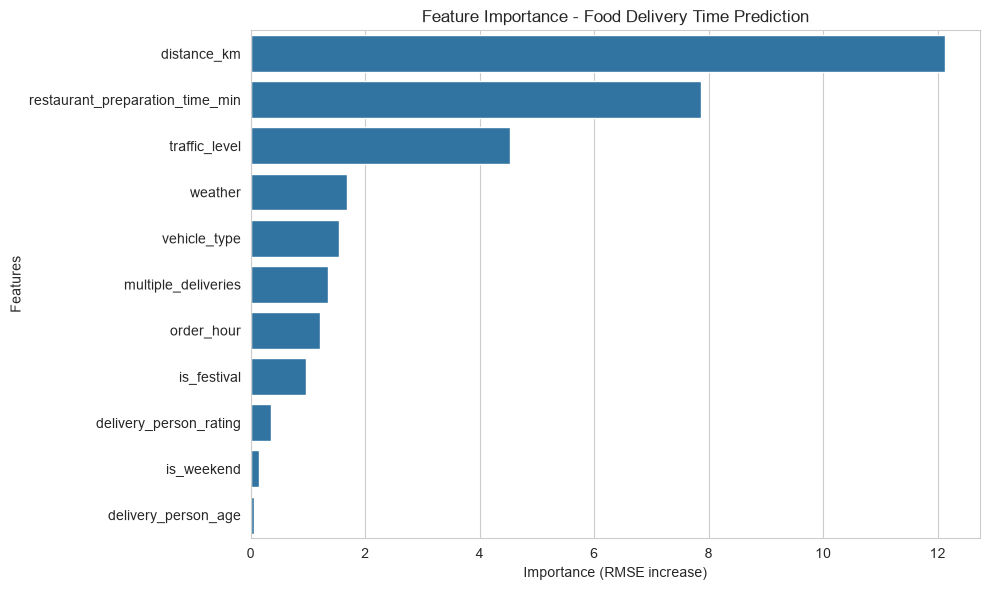

In [78]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Food Delivery Time Prediction")
plt.xlabel("Importance (RMSE increase)")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


In [79]:

prediction_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": test_predictions
})

prediction_df["Error"] = (
    prediction_df["Actual"] -
    prediction_df["Predicted"]
)

prediction_df["Absolute_Error"] = (
    prediction_df["Error"].abs()
)

print(prediction_df.head(10).round(2))


   Actual  Predicted  Error  Absolute_Error
0      36      35.39   0.61            0.61
1      69      68.08   0.92            0.92
2      43      43.70  -0.70            0.70
3      37      36.25   0.75            0.75
4      44      49.68  -5.68            5.68
5      58      60.33  -2.33            2.33
6      48      46.45   1.55            1.55
7      52      51.72   0.28            0.28
8      68      68.93  -0.93            0.93
9      64      65.70  -1.70            1.70


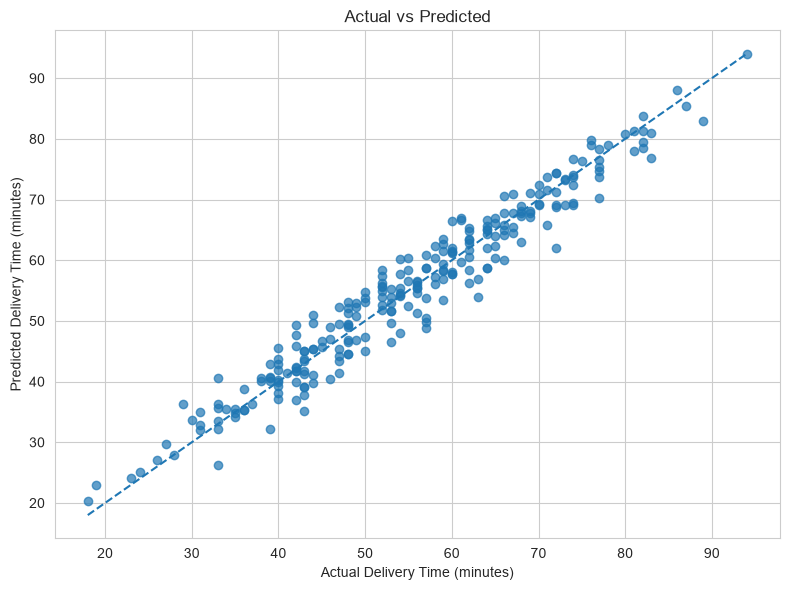

In [80]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.7
)

minimum = min(y_test.min(), test_predictions.min())
maximum = max(y_test.max(), test_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted")

plt.tight_layout()
plt.show()


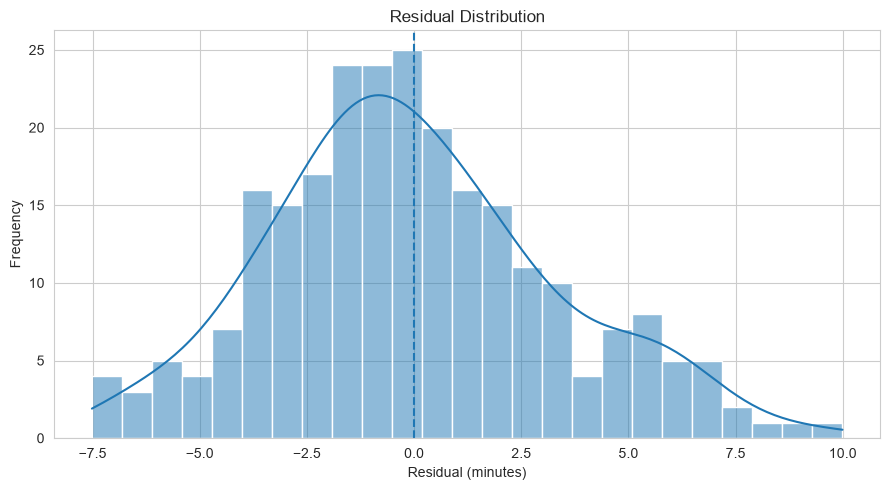

In [81]:

residuals = y_test.values - test_predictions

plt.figure(figsize=(9, 5))

sns.histplot(
    residuals,
    kde=True,
    bins=25
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("Residual (minutes)")
plt.ylabel("Frequency")
plt.title("Residual Distribution")

plt.tight_layout()
plt.show()


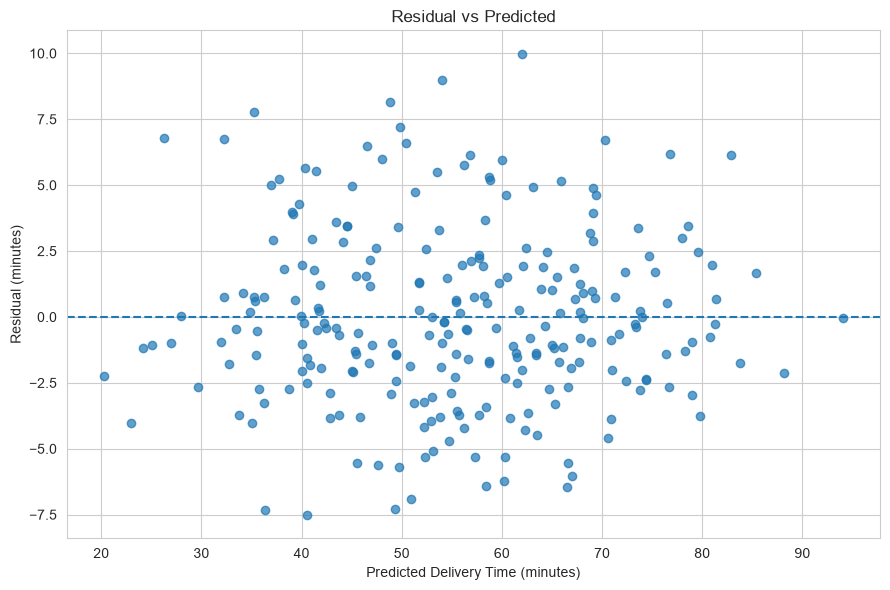

In [82]:

plt.figure(figsize=(9, 6))

plt.scatter(
    test_predictions,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Delivery Time (minutes)")
plt.ylabel("Residual (minutes)")
plt.title("Residual vs Predicted")

plt.tight_layout()
plt.show()


In [83]:

# Add original order IDs for reference
error_analysis = pd.DataFrame({
    "Order_ID": test["order_id"].values,
    "Actual_Time": y_test.values,
    "Predicted_Time": test_predictions,
    "Residual": residuals
})

error_analysis["Absolute_Error"] = (
    error_analysis["Residual"].abs()
)

# Show 10 orders with largest errors
worst_predictions = error_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

print(worst_predictions.round(2))


     Order_ID  Actual_Time  Predicted_Time  Residual  Absolute_Error
105      1106           72           62.01      9.99            9.99
123      1124           63           54.01      8.99            8.99
196      1197           57           48.86      8.14            8.14
103      1104           43           35.23      7.77            7.77
194      1195           33           40.52     -7.52            7.52
223      1224           29           36.31     -7.31            7.31
20       1021           42           49.29     -7.29            7.29
68       1069           57           49.81      7.19            7.19
146      1147           44           50.90     -6.90            6.90
139      1140           33           26.22      6.78            6.78


In [84]:
worst_order_ids = worst_predictions["Order_ID"]

print(
    test[test["order_id"].isin(worst_order_ids)]
)

     order_id  delivery_person_age  delivery_person_rating  distance_km  \
20       1021                   49                     3.4        10.24   
68       1069                   38                     2.6         4.49   
103      1104                   48                     3.2         5.72   
105      1106                   50                     4.9        11.60   
123      1124                   35                     2.9         8.28   
139      1140                   48                     4.7         1.03   
146      1147                   41                     4.0        17.11   
194      1195                   24                     2.7         1.11   
196      1197                   36                     2.7        17.77   
223      1224                   50                     4.5         5.14   

     restaurant_preparation_time_min traffic_level weather vehicle_type  \
20                                 6          High   Clear   Motorcycle   
68                      

In [85]:

traffic_error = pd.DataFrame({
    "Traffic": X_test["traffic_level"].values,
    "Actual": y_test.values,
    "Predicted": test_predictions
})

traffic_error["Absolute_Error"] = (
    traffic_error["Actual"] -
    traffic_error["Predicted"]
).abs()

traffic_summary = traffic_error.groupby(
    "Traffic"
)["Absolute_Error"].mean().reset_index()

traffic_summary = traffic_summary.sort_values(
    by="Absolute_Error",
    ascending=False
)

print(traffic_summary.round(2))


  Traffic  Absolute_Error
3  Medium            2.74
2     Low            2.70
0    High            2.53
1     Jam            2.13


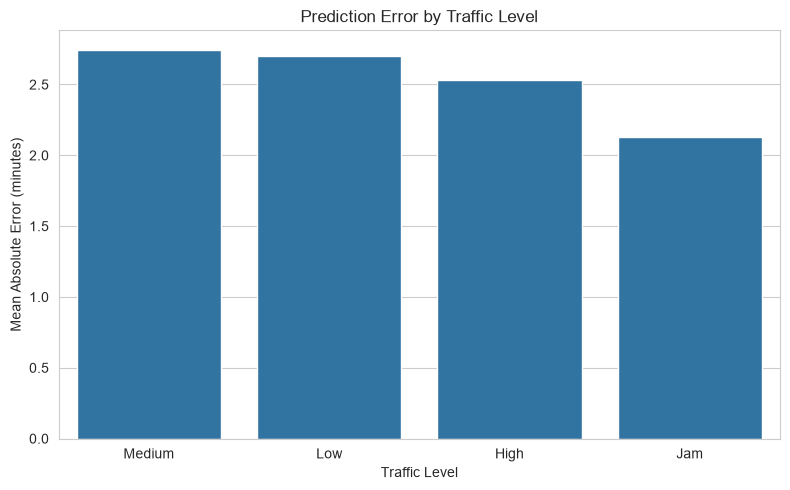

In [86]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=traffic_summary,
    x="Traffic",
    y="Absolute_Error"
)

plt.xlabel("Traffic Level")
plt.ylabel("Mean Absolute Error (minutes)")
plt.title("Prediction Error by Traffic Level")

plt.tight_layout()
plt.show()

In [87]:
print(X_test["traffic_level"].value_counts())

traffic_level
Medium    93
High      75
Low       64
Jam       18
Name: count, dtype: int64
